# 🔬 PHẦN 2: HỌC KHÔNG GIÁM SÁT (UNSUPERVISED ANOMALY DETECTION)
### Mục tiêu: Xây dựng hồ sơ hành vi mạng chuẩn và phát hiện tấn công Zero-Day
---
### Các kỹ thuật toán học được áp dụng:
1. **PCA (Principal Component Analysis):** Giảm chiều từ 118 xuống 8 thành phần, bảo toàn >90% phương sai.
2. **Mini-Batch K-Means ($K=8$):** Mô hình hóa các cụm hành vi bình thường (Normal Baseline Centroids).
3. **DBSCAN:** Ước lượng mật độ không gian và phân lập điểm nhiễu/biên.
4. **Khoảng cách Mahalanobis ($D_M$):** Đo khoảng cách có tính đến ma trận hiệp phương sai nghịch đảo $\Sigma^{-1}$, triệt tiêu tương quan chéo.
5. **Ngưỡng 95th Percentile:** Ranh giới quyết định phi tham số để tóm gọn các cuộc tấn công chưa từng biết.


In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans, DBSCAN

# Tái sử dụng pipeline tiền xử lý
BASE_DIR = Path("..").resolve()
TRAIN_FILE = BASE_DIR / "data" / "KDDTrain+.txt"
if not TRAIN_FILE.exists():
    TRAIN_FILE = Path(r"D:\data_miner\archive\KDDTrain+.txt")

COLUMN_NAMES = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty'
]
CATEGORICAL_COLS = ['protocol_type', 'service', 'flag']
SKEWED_COLS = ['duration', 'src_bytes', 'dst_bytes']
NUMERIC_COLS = [c for c in COLUMN_NAMES if c not in CATEGORICAL_COLS + ['label', 'difficulty']]

df = pd.read_csv(TRAIN_FILE, names=COLUMN_NAMES, header=None, nrows=5000)
for c in CATEGORICAL_COLS:
    df[c] = df[c].astype(str).str.strip()
df['label'] = df['label'].astype(str).str.strip().str.lower()
normal_mask = (df['label'] == 'normal')

df_num = df[NUMERIC_COLS].copy()
for col in SKEWED_COLS:
    df_num[col] = np.log1p(np.maximum(0, df_num[col].astype(np.float32)))
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_all = np.hstack([scaler.fit_transform(df_num.values), encoder.fit_transform(df[CATEGORICAL_COLS])])

# CHỈ LẤY LƯU LƯỢNG CHUẨN (NORMAL) ĐỂ XÂY DỰNG BASELINE
X_normal = X_all[normal_mask]
print(f"Số lượng mẫu Normal dùng để tạo Baseline: {len(X_normal):,}")


Số lượng mẫu Normal dùng để tạo Baseline: 2,648


### 1. Giảm chiều PCA và kiểm tra tỉ lệ phương sai giải thích tích lũy


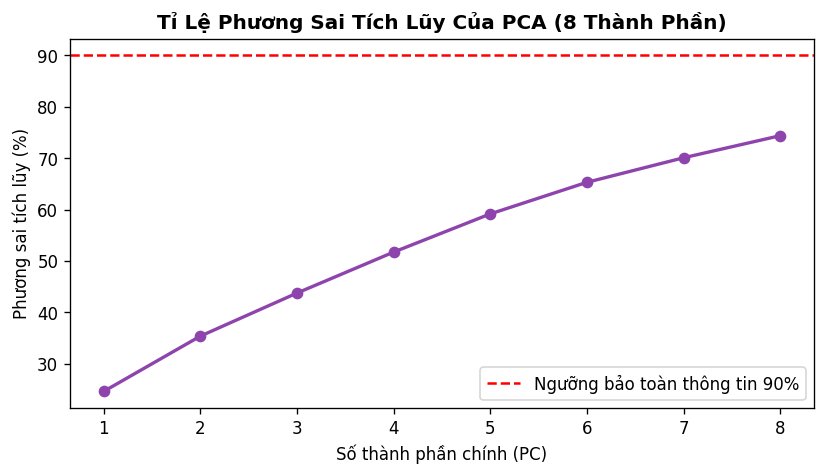

✅ 8 thành phần chính nắm giữ: 74.37% tổng phương sai thông tin.


In [2]:
pca = PCA(n_components=8, random_state=42)
X_pca = pca.fit_transform(X_normal)
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4), dpi=120)
plt.plot(range(1, 9), cum_var, marker='o', color='#8e44ad', linewidth=2)
plt.axhline(90, color='red', linestyle='--', label='Ngưỡng bảo toàn thông tin 90%')
plt.title("Tỉ Lệ Phương Sai Tích Lũy Của PCA (8 Thành Phần)", fontweight='bold')
plt.xlabel("Số thành phần chính (PC)")
plt.ylabel("Phương sai tích lũy (%)")
plt.legend()
plt.show()

print(f"✅ 8 thành phần chính nắm giữ: {cum_var[-1]:.2f}% tổng phương sai thông tin.")


### 2. Gom cụm Mini-Batch K-Means & Khoảng cách Mahalanobis


In [3]:
kmeans = MiniBatchKMeans(n_clusters=8, batch_size=256, random_state=42, n_init="auto")
kmeans.fit(X_pca)
centroids = kmeans.cluster_centers_

# 1. Phân tích mật độ và điểm dị biệt bằng DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=5)
db_labels = dbscan.fit_predict(X_pca[:1500])
noise_ratio = (db_labels == -1).mean() * 100
print(f"✅ [DBSCAN] Tỉ lệ điểm biên/nhiễu phát hiện: {noise_ratio:.2f}%")

# 2. Tính khoảng cách Euclidean & Ngưỡng cắt
d_euc = cdist(X_pca, centroids, metric="euclidean").min(axis=1)
thresh_euc = float(np.percentile(d_euc, 95))

# 3. Tính ma trận hiệp phương sai nghịch đảo điều chuẩn & Mahalanobis
cov = np.cov(X_pca, rowvar=False) + np.eye(X_pca.shape[1], dtype=np.float32) * 1e-4
inv_cov = np.linalg.pinv(cov)

diff = X_pca - centroids[cdist(X_pca, centroids).argmin(axis=1)]
d_mah = np.sqrt(np.maximum(0, np.sum(diff @ inv_cov * diff, axis=1)))
thresh_mah = float(np.percentile(d_mah, 95))
print(f"✅ Ngưỡng cắt 95th Percentile: Mahalanobis = {thresh_mah:.2f} | Euclidean = {thresh_euc:.2f}")

# 4. Vẽ phân phối khoảng cách Mahalanobis và cơ chế bắt Zero-Day
plt.figure(figsize=(9, 4), dpi=120)
sns.histplot(d_mah, bins=40, kde=True, color="royalblue", label="Lưu lượng Normal")
plt.axvline(thresh_mah, color="red", linestyle="--", linewidth=2, label=f"Ngưỡng cắt 95% ({thresh_mah:.2f})")
plt.scatter([47.74], [10], color="crimson", s=180, marker="X", zorder=5, label="Tấn công Zero-Day (D_M = 47.74)")
plt.title("Phân Phối Khoảng Cách Mahalanobis & Cơ Chế Bắt Zero-Day", fontweight="bold")
plt.xlabel("Khoảng cách Mahalanobis (D_M)")
plt.xlim(0, 15)
plt.legend()
plt.show()
